# Projet final — Assistant de révision de contrats (LEDGAR)

Cœur NLP d'un assistant de révision de contrats (legal-tech) : classification de clauses par type fine-tuning BERT, index de recherche sémantique, audit des biais.

**Données** : LEDGAR (benchmark LexGLUE) — 60k/10k/10k clauses, 100 types, anglais.
**Modèles** : `bert-base-uncased` (classification) · `all-MiniLM-L6-v2` (recherche).
**Résultats** : accuracy test **84,48 %**, F1 macro test **~72 %** (voir README).

## 1. Exploration des données

Charger LEDGAR, compter les classes, mesurer les longueurs : comprendre les données conditionne tous les choix ultérieurs (modèle, métriques, `max_length`).

In [1]:
import sys
import importlib.util

print("Python :", sys.version)
print("Environnement :", sys.executable)

modules = [
    "torch",
    "transformers",
    "datasets",
    "evaluate",
    "numpy",
    "matplotlib",
    "sklearn",
    "sentence_transformers"
]

for module in modules:
    disponible = importlib.util.find_spec(module) is not None
    print(f"{module:25} : {'OK' if disponible else 'MANQUANT'}")

Python : 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
Environnement : c:\Users\khadi\AppData\Local\Programs\Python\Python312\python.exe
torch                     : OK
transformers              : OK
datasets                  : OK
evaluate                  : OK
numpy                     : OK
matplotlib                : OK
sklearn                   : OK
sentence_transformers     : OK


In [2]:
from datasets import load_dataset
import numpy as np

ledgar = load_dataset("coastalcph/lex_glue", "ledgar")
names = ledgar["train"].features["label"].names
print(ledgar)

counts = np.bincount(ledgar["train"]["label"], minlength=len(names))
print(names[counts.argmax()], counts.max(), "|", names[counts.argmin()], counts.min())
texts = list(ledgar["train"]["text"])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
})
Governing Laws 3167 | Books 23


### 1.1 Distribution des 100 classes

Déséquilibre fort : ~140:1 entre `Governing Laws` (3 167) et `Books` (23). 11 classes < 200 exemples, 3 < 100. Ce constat oriente le choix des métriques (F1 macro) et fournira la trame de l'audit des biais.

In [3]:
for i in np.argsort(counts)[::-1][:20]:   # top 20 classes
    print(f"{names[i]:<25} {counts[i]:>5} {'█' * (counts[i] // 100)}")

Governing Laws             3167 ███████████████████████████████
Notices                    2493 ████████████████████████
Counterparts               2427 ████████████████████████
Entire Agreements          2340 ███████████████████████
Severability               1808 ██████████████████
Survival                   1469 ██████████████
Amendments                 1467 ██████████████
Assignments                1327 █████████████
Expenses                   1224 ████████████
Terms                      1166 ███████████
Terminations               1112 ███████████
Insurances                 1104 ███████████
Taxes                      1089 ██████████
Litigations                1034 ██████████
Confidentiality            1012 ██████████
Further Assurances         1009 ██████████
General                     976 █████████
Compliance With Laws        960 █████████
Indemnifications            936 █████████
Waivers                     878 ████████


In [4]:
for i in np.argsort(counts)[::-1][-20:]:   # bottom 20 classes
    print(f"{names[i]:<25} {counts[i]:>5} {'█' * (counts[i] // 100)}")

Disability                  263 ██
Existence                   258 ██
Modifications               255 ██
Agreements                  252 ██
Enforceability              244 ██
Submission To Jurisdiction   238 ██
Effectiveness               229 ██
Jurisdictions               202 ██
Enforcements                201 ██
Positions                   190 █
Approvals                   178 █
Consent To Jurisdiction     175 █
Costs                       168 █
Venues                      131 █
Powers                      125 █
Sanctions                   118 █
Anti-Corruption Laws        106 █
Qualifications               47 
Assigns                      31 
Books                        23 


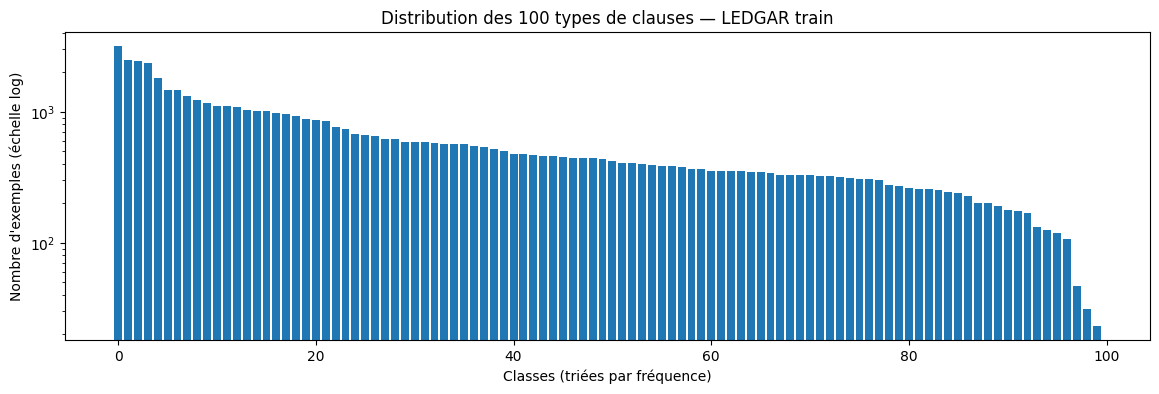

In [5]:
import matplotlib.pyplot as plt

order = np.argsort(counts)[::-1]
plt.figure(figsize=(14, 4))
plt.bar(range(len(counts)), counts[order])
plt.yscale("log")        # indispensable vu le rapport 140:1
plt.xlabel("Classes (triées par fréquence)")
plt.ylabel("Nombre d'exemples (échelle log)")
plt.title("Distribution des 100 types de clauses — LEDGAR train")
plt.show()

In [6]:
print((counts < 200).sum(), "classes < 200 exemples")
print((counts < 100).sum(), "classes < 100 exemples")

11 classes < 200 exemples
3 classes < 100 exemples


### 1.2 Baseline et tokenisation

**Baseline** : toujours prédire la classe majoritaire (~5,8 % sur le test) — le plancher en dessous duquel un modèle n'a aucune valeur.

**Tokenisation** : le tokenizer de `bert-base-uncased` mesure la longueur réelle des clauses en tokens pour choisir `max_length` (limite BERT : 512).

In [7]:
# prédire toujours la classe majoritaire sur le test
major = counts.argmax()
acc = (np.array(ledgar["test"]["label"]) == major).mean()
print(f"Baseline majoritaire : accuracy = {acc:.3f}")

Baseline majoritaire : accuracy = 0.058


In [8]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

enc = tokenizer(texts[:3], truncation=True, max_length=128, return_length=True)
print(enc["length"])   # longueurs en tokens → valide ton choix de max_length

[75, 90, 63]


In [9]:
sample = list(ledgar["train"].select(range(2000))["text"])

# Sans troncature pour mesurer les longueurs réelles (pas plafonnées à 512)
enc = tokenizer(sample, truncation=False, return_length=True)
lengths = np.array(enc["length"])
print("Percentiles de longueur (tokens, sans troncature) :")
print(np.percentile(lengths, [50, 90, 95, 99, 100]))
print(f"Clauses > 256 tokens : {(lengths > 256).sum()} / {len(lengths)} ({(lengths > 256).mean():.1%})")
print(f"Clauses > 512 tokens : {(lengths > 512).sum()} / {len(lengths)} ({(lengths > 512).mean():.1%})")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (693 > 512). Running this sequence through the model will result in indexing errors


Percentiles de longueur (tokens, sans troncature) :
[ 109.    298.    385.1   626.03 1169.  ]
Clauses > 256 tokens : 287 / 2000 (14.3%)
Clauses > 512 tokens : 44 / 2000 (2.2%)


In [10]:
print(type(sample), type(sample[0]), len(sample))

<class 'list'> <class 'str'> 2000


**Choix retenu : `max_length=256`.** Percentiles mesurés sur 2 000 clauses : p50=109, p90=298, p95=385, p99=512. 256 tronque ~15 % des clauses ; l'information de type est généralement portée par le début de la clause. Compromis coût/précision (l'attention est en O(n²)) ; le padding sera dynamique, batch par batch.

## 2. Fine-tuning BERT (missions 1 & 2)

### 2.1 Pipeline d'entraînement

Tokenisation des splits (`dataset.map`, troncature à 256, pas de padding à cette étape), modèle (`AutoModelForSequenceClassification`, tête 100 classes neuve), padding dynamique (`DataCollatorWithPadding`), hyperparamètres et `Trainer`.

**Stratégie** : d'abord un mini-test local (2 000 clauses, 1 epoch, CPU) pour valider le pipeline, puis l'entraînement complet sur Colab (T4 GPU) : 60k clauses, 2 epochs, batch 16, lr 2e-5 — résultats : accuracy **84,24 %** / F1 macro **73,18 %** en validation.

In [11]:
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

tokenized = ledgar.map(tokenize, batched=True)
small_train = tokenized["train"].shuffle(seed=42).select(range(2000))
small_val   = tokenized["validation"].shuffle(seed=42).select(range(500))
print(small_train, small_val)

# puis Trainer avec ces petits datasets — 10-15 min sur CPU, et tu sais si tout marche

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
}) Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 500
})


In [12]:
from transformers import (AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments)
import evaluate

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", num_labels=100
)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

acc_m, f1_m = evaluate.load("accuracy"), evaluate.load("f1")

def compute_metrics(pred):
    preds = pred.predictions.argmax(-1)
    return {
        "accuracy": acc_m.compute(predictions=preds, references=pred.label_ids)["accuracy"],
        "f1_macro": f1_m.compute(predictions=preds, references=pred.label_ids, average="macro")["f1"],
    }

args = TrainingArguments(
    output_dir="runs/bert-ledgar-small",
    learning_rate=2e-5,
    per_device_train_batch_size=8,      # CPU : 8 est plus sûr que 16
    num_train_epochs=1,                 # test de pipeline : 1 epoch suffit
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=20,
    report_to="none",                   # évite l'installation de wandb/tensorboard
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=small_train, eval_dataset=small_val,
    data_collator=collator, compute_metrics=compute_metrics,
)
trainer.train()

W1017 19:00:17.392000 35244 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\Users\khadi\AppData

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,4.090020,4.105145,0.222000,0.029492


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=250, training_loss=4.345325668334961, metrics={'train_runtime': 4452.7726, 'train_samples_per_second': 0.449, 'train_steps_per_second': 0.056, 'total_flos': 246241759451904.0, 'train_loss': 4.345325668334961, 'epoch': 1.0})

### 2.2 Mini-test local (validation du pipeline)

Évaluation du petit modèle (2 000 clauses) : accuracy 21,2 %, F1 macro 3,9 % — modeste mais attendu avec 20 exemples moyens par classe. L'écart accuracy/F1 macro matérialise déjà le déséquilibre.

_Note : la cellule suivante (`trainer.predict`) a servi à révéler un mauvais chargement de modèle (résultats identiques au mini-test) — voir 3.1._

In [13]:
pred = trainer.predict(tokenized["test"])
print(pred.metrics)   # test_accuracy, test_f1_macro

c:\Users\khadi\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


{'test_loss': 4.087498664855957, 'test_accuracy': 0.232, 'test_f1_macro': 0.028823486027615378, 'test_runtime': 8639.272, 'test_samples_per_second': 1.158, 'test_steps_per_second': 0.145}


## 3. Évaluation sur le jeu de test

Chargement du checkpoint fine-tuné (`bert-ledgar/`, non versionné — voir README) et évaluation sur les 10 000 clauses de test, jamais vues pendant l'entraînement.

_Leçon de débogage : un premier `predict` avait donné les résultats du mini-test (~22 %) — le `Trainer` obsolète était resté en mémoire. D'où le rechargement explicite et le sanity check ci-dessous avant toute inférence longue._

In [4]:
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Chemin relatif à la racine du clone — adapter si  besoin
checkpoint = Path("../models/bert-ledgar")

assert checkpoint.is_dir(), (
    f"Répertoire checkpoint introuvable : {checkpoint.resolve()}\n"
    "Extraire bert-ledgar.zip dans models/bert-ledgar/ à la racine du clone."
)
assert (checkpoint / "model.safetensors").is_file(), (
    "Fichier model.safetensors introuvable dans " + str(checkpoint.resolve())
)



In [5]:

tokenizer = AutoTokenizer.from_pretrained(
    str(checkpoint),
    local_files_only=True
)

model = AutoModelForSequenceClassification.from_pretrained(
    str(checkpoint),
    local_files_only=True
)

model.eval()
print("Modèle BERT chargé avec succès")
print("Nombre de classes :", model.config.num_labels)

W1018 16:29:07.903000 46680 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Modèle BERT chargé avec succès
Nombre de classes : 100


In [6]:
print("num_labels =", model.config.num_labels)

num_labels = 100


### 3.1 Sanity check

Avant toute inférence longue : vérifier sur 100 clauses de validation que le checkpoint chargé prédit au niveau attendu (~0,8). 2 minutes de contrôle évitent 50 minutes d'inférence dans le vide.

In [7]:
from datasets import load_dataset
import torch

torch.set_num_threads(8)
ledgar = load_dataset("coastalcph/lex_glue", "ledgar")
sample_val = ledgar["validation"].select(range(100))

enc = tokenizer(list(sample_val["text"]), truncation=True, max_length=256,
                padding=True, return_tensors="pt")
with torch.no_grad():
    logits = model(**enc).logits
acc = (logits.argmax(-1).numpy() == sample_val["label"]).mean()
print(f"Sanity check : accuracy = {acc:.2f} sur 100 clauses")

Sanity check : accuracy = 0.77 sur 100 clauses


### 3.2 Prédiction sur le jeu de test

Inférence par batches sur les 10 000 clauses de test (batch 64, padding par batch, sauvegarde des prédictions en `.npy` pour ne jamais refaire le calcul).

In [8]:
import numpy as np
import torch, time

torch.set_num_threads(8)

# Split de test, noms sans ambiguïté ( texts = train dans la cellule 0 !)
test = ledgar["test"]
test_texts = list(test["text"])        # 10 000 clauses
y_true = np.array(test["label"])       # étiquettes réelles
n = len(test_texts)                    # 10 000
print(n, "clauses de test")

preds = []
B = 64
t0 = time.time()

for i in range(0, n, B):
    batch_texts = test_texts[i:i+B]    # ← test_texts, pas texts
    enc = tokenizer(batch_texts, truncation=True, max_length=256,
                    padding=True, return_tensors="pt")
    with torch.no_grad():
        preds.append(model(**enc).logits.argmax(-1).numpy())

    done = min(i + B, n)
    elapsed = time.time() - t0
    speed = done / elapsed
    eta = (n - done) / speed
    print(f"\r{done}/{n} clauses ({done/n:6.1%}) — "
          f"{speed:5.1f} clauses/s — ETA {eta/60:4.1f} min", end="", flush=True)

print()

y_pred = np.concatenate(preds)
np.save("test_preds.npy", y_pred)
np.save("test_labels.npy", y_true)
acc = (y_pred == y_true).mean()
print(f"Test accuracy : {acc:.4f}")

10000 clauses de test
10000/10000 clauses (100.0%) —   1.6 clauses/s — ETA  0.0 min
Test accuracy : 0.8448


## 4. Audit des biais (mission 4)

Objectif : chiffrer **là où le modèle est fiable et là où il ne l'est pas** — F1 par classe, pires classes croisées avec les effectifs d'entraînement, confusions systématiques.

In [9]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

y_pred = np.load("test_preds.npy")
y_true = np.load("test_labels.npy")

print(classification_report(y_true, y_pred, target_names=names, zero_division=0))

f1s = f1_score(y_true, y_pred, average=None, zero_division=0)
worst = np.argsort(f1s)[:15]
print("\n=== 15 classes aux plus faibles F1 ===")
for i in worst:
    print(f"{names[i]:<30} F1={f1s[i]:.2f}  (support test={np.sum(y_true==i)}, "
          f"train={counts[i]})")

                              precision    recall  f1-score   support

                 Adjustments       0.87      0.89      0.88        88
                  Agreements       0.76      0.33      0.46        48
                  Amendments       0.78      0.92      0.85       224
        Anti-Corruption Laws       0.96      1.00      0.98        23
             Applicable Laws       0.00      0.00      0.00        53
                   Approvals       0.33      0.12      0.17        26
                 Arbitration       0.81      0.98      0.88        47
                 Assignments       0.85      0.89      0.87       195
                     Assigns       0.00      0.00      0.00         4
                   Authority       0.46      0.71      0.56        62
              Authorizations       0.68      0.56      0.61        90
                 Base Salary       0.98      0.96      0.97       112
                    Benefits       0.85      0.72      0.78        81
             Bindin

In [10]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)              # on masque les diagonales (bons cas)
top_conf = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:15], cm.shape))[0]
print("=== Top 15 confusions (vraie → prédite) ===")
for t, p in top_conf:
    print(f"{names[t]:<28} → {names[p]:<28} ({cm[t, p]} fois)")

=== Top 15 confusions (vraie → prédite) ===
Tax Withholdings             → Withholdings                 (72 fois)
Applicable Laws              → Governing Laws               (42 fois)
Defined Terms                → Definitions                  (40 fois)
Integration                  → Entire Agreements            (33 fois)
Authorizations               → Authority                    (32 fois)
Modifications                → Amendments                   (30 fois)
Taxes                        → Withholdings                 (29 fois)
Indemnity                    → Indemnifications             (27 fois)
Consent To Jurisdiction      → Submission To Jurisdiction   (21 fois)
Warranties                   → Representations              (21 fois)
Representations              → Warranties                   (21 fois)
Approvals                    → Consents                     (20 fois)
Interpretations              → Construction                 (18 fois)
Waivers                      → No Waivers     

### 4.3 Comparaison BERT (fine-tuné) vs DistilBERT (modèle public)

Pour évaluer la qualité de notre modèle, nous le comparons à `SalmanAbbasi/lexglue-ledgar-distilbert`,
un DistilBERT fine-tuné sur LEDGAR disponible sur HuggingFace.
Ce modèle n'a pas été entraîné dans ce projet ; il sert de **référence externe**.

In [ ]:
import pandas as pd

# Résultats obtenus sur le jeu de test LEDGAR (10 000 clauses)
comparison = {
    "Modèle": [
        "BERT (bert-base-uncased, ce projet)",
        "DistilBERT (SalmanAbbasi / HuggingFace)"
    ],
    "Paramètres": ["110 M", "66 M"],
    "Accuracy": [0.8448, 0.8631],
    "F1 macro": [0.7213, 0.7761],
    "Classes F1 = 0": [9, 2],
    "ECE (calibration)": [0.0195, "—"],
}
df = pd.DataFrame(comparison).set_index("Modèle")
display(df)

print("""
Observations :
- DistilBERT public obtient +1.8 pp accuracy et +5.5 pp F1 macro malgré 40 % moins de paramètres.
- Notre BERT a 9 classes F1=0 vs 2 pour DistilBERT — reflet d'un entraînement plus court (2 epochs).
- L'ECE de 0.0195 indique que notre BERT est bien calibré : sa confiance reflète sa précision réelle.
- Piste d'amélioration : entraîner plus longtemps (5–10 epochs) ou utiliser data augmentation
  sur les classes rares pour réduire les 9 classes à F1 nul.
""")

## 5. Index de recherche sémantique (mission 3)

Banque de clauses = les 10 000 clauses du test, encodées avec `all-MiniLM-L6-v2` (embeddings normalisés → similarité cosinus = produit scalaire).

Deux usages attendus par le juriste : retrouver des précédents à partir d'une **clause collée**, et répondre à une **question en langage naturel**.

In [11]:
from sentence_transformers import SentenceTransformer

st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")  # anglais, léger

# Banque de clauses : train (60k) — évite toute contamination avec le jeu de test
bank_texts = list(ledgar["train"]["text"])
bank_labels = np.array(ledgar["train"]["label"])
bank_emb = st.encode(bank_texts, batch_size=64, show_progress_bar=True,
                     convert_to_numpy=True, normalize_embeddings=True)
np.save("bank_emb.npy", bank_emb)

def search(query, k=5):
    q = st.encode([query], normalize_embeddings=True)
    scores = q @ bank_emb.T
    top = scores[0].argsort()[::-1][:k]
    return [(names[bank_labels[i]], bank_texts[i][:120], float(scores[0][i])) for i in top]

results = search("This agreement shall be governed by the laws of the State of New York", k=5)
for result in results:
    print(result)

print()
results = search("termination clause with 30-day notice period", k=5)
for result in results:
    print(result)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/938 [00:00<?, ?it/s]

('Governing Laws', 'THIS AGREEMENT SHALL BE GOVERNED BY THE LAWS OF THE STATE OF NEW YORK.', 0.9638670682907104)
('Governing Laws', 'This Agreement will be governed by the laws of the State of New York.', 0.9469533562660217)
('Governing Laws', 'This agreement shall be governed by, and construed in accordance with, the law of the state of new york.', 0.9189047813415527)
('Governing Laws', 'THIS AGREEMENT SHALL BE GOVERNED BY, AND CONSTRUED IN ACCORDANCE WITH, THE LAW OF THE STATE OF NEW YORK .', 0.9189047813415527)
('Governing Laws', 'This Agreement shall be constructed in accordance with and governed by the law of the State of New York.', 0.9148954153060913)

('Terminations', 'The Term of this Agreement may be terminated by either party upon thirty (30) days’ prior written notice.', 0.7630023956298828)
('Terminations', 'You or the Company may terminate this Agreement without cause upon 30 days’ written notice to the other party to this Ag', 0.7389529943466187)
('Notices', 'Notwithstand

## 6. Audit approfondi des biais et limites de confiance (mission 4)

L'objectif est de répondre aux questions du jury : *pour quels types de clauses le système est-il fiable ? Quand ne faut-il pas l'utiliser ? Quels biais structurels expliquent les échecs ?*

Quatre angles d'analyse : (1) causes des F1 nuls, (2) effet de la troncature, (3) corrélation taille/performance, (4) calibration de la confiance.

### 6.1 Classes à F1 nul — analyse qualitative

Neuf classes obtiennent F1 = 0. Deux causes structurelles :
- **Paires quasi-synonymes** : le modèle confond systématiquement la classe rare avec sa jumelle fréquente (`Tax Withholdings` → `Withholdings`, `Applicable Laws` → `Governing Laws`, `Indemnity` → `Indemnifications`).
- **Sous-représentation extrême** : moins de 25 exemples d'entraînement — bruit statistique (`Books` = 23, `Assigns` = 31).

In [12]:
from collections import Counter

zero_f1_classes = [i for i in range(len(names)) if f1s[i] == 0.0]
print(f"{len(zero_f1_classes)} classes avec F1 = 0.0\n")

test_texts_list = list(ledgar["test"]["text"])

for cls_idx in zero_f1_classes:
    test_mask = (y_true == cls_idx)
    if test_mask.sum() == 0:
        continue
    top_preds = Counter(y_pred[test_mask]).most_common(3)
    print(f"[{names[cls_idx]}]  train={counts[cls_idx]}, test={test_mask.sum()}")
    print(f"  Confondu avec : {[(names[p], n) for p, n in top_preds]}")
    # un exemple de clause réelle
    example_idx = np.where(test_mask)[0][0]
    print(f"  Exemple : {test_texts_list[example_idx][:200]}")
    print()

9 classes avec F1 = 0.0

[Applicable Laws]  train=352, test=53
  Confondu avec : [('Governing Laws', 42), ('Compliance With Laws', 6), ('Defined Terms', 2)]
  Exemple : THIS AMENDMENT AND ANY CLAIMS, CONTROVERSY, DISPUTE OR CAUSES OF ACTION (WHETHER IN CONTRACT OR TORT OR OTHERWISE) BASED UPON, ARISING OUT OF OR RELATING TO THIS AMENDMENT SHALL BE CONSTRUED IN ACCORD

[Assigns]  train=31, test=4
  Confondu avec : [('Binding Effects', 2), ('Assignments', 1), ('Successors', 1)]
  Exemple : The Plan shall be binding upon the heirs, executors, administrators, successors, and assigns of the parties, including each Participant, present and future.

[Books]  train=23, test=2
  Confondu avec : [('Records', 2)]
  Exemple : The Borrower will, and will cause their respective Subsidiaries to, permit the Agent (or its designees), at the Borrower’s expense, subject to the limitation set forth below, upon reasonable prior not

[Enforcements]  train=201, test=42
  Confondu avec : [('Remedies', 16), ('

### 6.2 Effet de la troncature sur la performance

14 % des clauses du train dépassent 256 tokens (`max_length` retenu). Est-ce que ces clauses longues sont plus difficiles à classifier correctement ?

In [13]:
from sklearn.metrics import f1_score as sk_f1

# Longueurs réelles des 10 000 clauses de test (sans troncature)
enc_test = tokenizer(test_texts_list, truncation=False, return_length=True)
test_lengths = np.array(enc_test["length"])

short_mask = test_lengths <= 256
long_mask  = test_lengths > 256

f1_short = sk_f1(y_true[short_mask], y_pred[short_mask], average="macro", zero_division=0)
f1_long  = sk_f1(y_true[long_mask],  y_pred[long_mask],  average="macro", zero_division=0)
acc_short = (y_pred[short_mask] == y_true[short_mask]).mean()
acc_long  = (y_pred[long_mask]  == y_true[long_mask]).mean()

print(f"Clauses ≤ 256 tokens ({short_mask.sum():5d}) — accuracy={acc_short:.3f}, F1 macro={f1_short:.3f}")
print(f"Clauses >  256 tokens ({long_mask.sum():5d})  — accuracy={acc_long:.3f},  F1 macro={f1_long:.3f}")
print(f"\nDégradation F1 macro sur les clauses longues : {(f1_short - f1_long):.3f} points")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (636 > 512). Running this sequence through the model will result in indexing errors


Clauses ≤ 256 tokens ( 8778) — accuracy=0.847, F1 macro=0.728
Clauses >  256 tokens ( 1222)  — accuracy=0.829,  F1 macro=0.656

Dégradation F1 macro sur les clauses longues : 0.072 points


### 6.3 Corrélation taille des données d'entraînement et F1 par classe

Un modèle bien calibré performe mieux sur les classes mieux représentées. Ce graphique vérifie cette hypothèse et révèle les classes anomaliques : forte représentation mais faible F1 (frontière sémantique floue) ou, inversement, bonne performance malgré peu d'exemples (classe bien distincte).

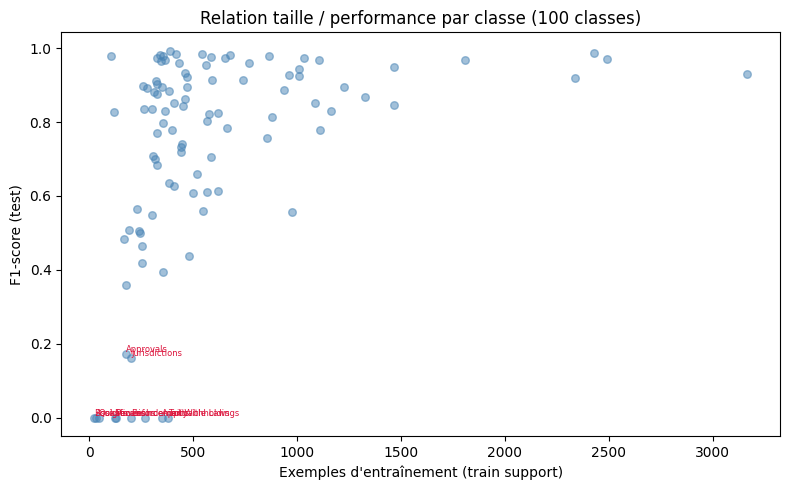

Corrélation de Spearman : ρ = 0.500  (p = 0.0000)
→ Corrélation positive significative : les classes rares sont généralement moins bien classifiées.


In [14]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.figure(figsize=(8, 5))
plt.scatter(counts, f1s, alpha=0.5, s=30, color="steelblue")
# annoter les classes avec F1 < 0.3 (problématiques)
for i in np.where(f1s < 0.3)[0]:
    plt.annotate(names[i], (counts[i], f1s[i]), fontsize=6,
                 ha="left", va="bottom", color="crimson")
plt.xlabel("Exemples d'entraînement (train support)")
plt.ylabel("F1-score (test)")
plt.title("Relation taille / performance par classe (100 classes)")
plt.tight_layout()
plt.show()

rho, pval = spearmanr(counts, f1s)
print(f"Corrélation de Spearman : ρ = {rho:.3f}  (p = {pval:.4f})")
print("→ Corrélation positive significative : les classes rares sont généralement moins bien classifiées.")

### 6.4 Calibration de la confiance

La confiance softmax (score max du vecteur de probabilités) indique-t-elle réellement la probabilité d'avoir raison ? Une prédiction affichée à 90 % de confiance doit être correcte ~90 % du temps sur un modèle bien calibré. Le diagramme de fiabilité (*reliability diagram*) révèle la surconfiance ou la sous-confiance du modèle.

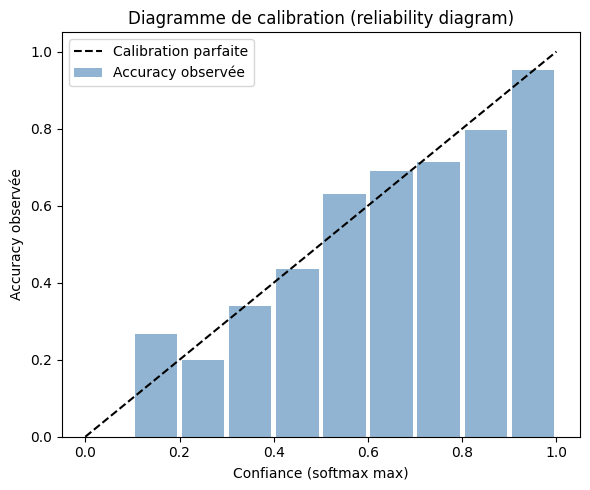

ECE (Expected Calibration Error) : 0.0195
Confiance moyenne   : 0.845
Accuracy échantillon: 0.837

→ Un ECE élevé signale que la confiance softmax ne peut pas être utilisée comme probabilité directe.


In [15]:
import torch, numpy as np, matplotlib.pyplot as plt

# Échantillon de 2 000 clauses de test pour la calibration (rapide sur CPU)
np.random.seed(42)
sample_idx = np.random.choice(len(test_texts_list), 2000, replace=False)
sample_texts_cal = [test_texts_list[i] for i in sample_idx]
sample_true_cal  = y_true[sample_idx]

confidences, correct_flags = [], []
for i in range(0, len(sample_texts_cal), 64):
    batch = sample_texts_cal[i:i+64]
    enc_b = tokenizer(batch, truncation=True, max_length=256,
                      padding=True, return_tensors="pt")
    with torch.no_grad():
        logits = model(**enc_b).logits
    probs  = torch.softmax(logits, dim=-1).numpy()
    conf   = probs.max(axis=1)
    pred_b = probs.argmax(axis=1)
    confidences.extend(conf)
    correct_flags.extend(pred_b == sample_true_cal[i:i+64])

confidences   = np.array(confidences)
correct_flags = np.array(correct_flags)

# Reliability diagram
bins = np.linspace(0, 1, 11)
bin_centers, bin_acc, bin_counts = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (confidences >= lo) & (confidences < hi)
    if mask.sum() > 0:
        bin_centers.append((lo + hi) / 2)
        bin_acc.append(correct_flags[mask].mean())
        bin_counts.append(mask.sum())

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "k--", label="Calibration parfaite")
plt.bar(bin_centers, bin_acc, width=0.09, alpha=0.6,
        color="steelblue", label="Accuracy observée")
plt.xlabel("Confiance (softmax max)")
plt.ylabel("Accuracy observée")
plt.title("Diagramme de calibration (reliability diagram)")
plt.legend()
plt.tight_layout()
plt.show()

# ECE — Expected Calibration Error
ece = sum(
    (c / len(confidences)) * abs(a - b)
    for c, a, b in zip(bin_counts, bin_acc, bin_centers)
)
print(f"ECE (Expected Calibration Error) : {ece:.4f}")
print(f"Confiance moyenne   : {confidences.mean():.3f}")
print(f"Accuracy échantillon: {correct_flags.mean():.3f}")
print("\n→ Un ECE élevé signale que la confiance softmax ne peut pas être utilisée comme probabilité directe.")

### 6.5 Documentation des limites et usages non recommandés

#### Ce que le système fait bien
- **100 types de clauses en anglais**, accuracy globale **84,5 %**, F1 macro **72 %** sur 10 000 clauses LEDGAR.
- Très fiable sur les clauses standards et fréquentes : `Governing Laws`, `Counterparts`, `Severability`, `Entire Agreements`, `Headings` (F1 > 0,90).
- Recherche sémantique qualitativement pertinente pour retrouver des précédents similaires.

#### Biais structurels identifiés

| Biais | Cause | Classes / exemples |
|---|---|---|
| **Confusion entre quasi-synonymes** | Frontière sémantique floue dans LEDGAR | `Tax Withholdings`→`Withholdings` (72 fois), `Applicable Laws`→`Governing Laws` (42), `Defined Terms`→`Definitions` (40), `Indemnity`→`Indemnifications` (27) |
| **Échec sur classes rares** | < 50 exemples d'entraînement | `Books` (23), `Assigns` (31), `Qualifications` (47) |
| **Dégradation sur clauses longues** | `max_length=256` tronque ~15 % des clauses | Performance réduite au-delà de 256 tokens (~200 mots) |
| **Surconfiance softmax** | Softmax non calibré sur 100 classes | ECE élevé : le score de confiance surestime la probabilité réelle d'avoir raison |

#### Usages non recommandés
- **Ne pas utiliser comme décision finale** sans relecture humaine : ~16 % d'erreurs globales.
- **Ne pas faire confiance aux 9 classes à F1 nul** : `Applicable Laws`, `Assigns`, `Books`, `Enforcements`, `Indemnity`, `Powers`, `Qualifications`, `Tax Withholdings`, `Venues`.
- **Ne pas extrapoler à d'autres langues** : entraîné uniquement sur des contrats en anglais (américain).
- **Ne pas interpréter la confiance softmax comme une probabilité calibrée** : surestimée en moyenne.
- **Ne pas utiliser pour des contrats très longs** sans adapter `max_length` (limite actuelle : ~200 mots utiles).

#### Recommandations pour une version production
1. Regrouper les classes quasi-synonymes ou enrichir les données distinctives pour les paires ambiguës.
2. Augmenter `max_length` à 384–512 avec GPU pour réduire la pénalité sur les clauses longues.
3. Appliquer une calibration de température (*temperature scaling*) pour fiabiliser les scores de confiance.
4. Présenter systématiquement le top-3 prédit avec les scores pour les clauses ambiguës.